## **YOLOv8 Retrain (Roboflow + pseudo-labels)**
Retrains the `best.pt` saved on Drive using **Roboflow accident datasets only** (same format as `Roboflow_Accidents.zip`: `data.yaml`, `train/`, `valid/`, `test/`, each with `images/` and `labels/`).

- Only the `accident` boxes of the dataset are kept; vehicles are re-labeled by a COCO-pretrained YOLOv8x (pseudo-labels), like in the training notebook.
- Validation = holdout of the Roboflow images (A9 is not used).
- The original `best.pt` is **not** overwritten: the result is saved as `best_retrain.pt`.

## 1. Install ultralytics

In [7]:
!pip install -U ultralytics -q
from IPython import display
display.clear_output()
!yolo settings sync=False

✅ Updated 'sync=False'
JSONDict("/root/.config/Ultralytics/settings.json"):
{
  "settings_version": "0.0.8",
  "datasets_dir": "/content/datasets",
  "weights_dir": "weights",
  "runs_dir": "runs",
  "uuid": "8de2fe1f8f3469ef31ec77adb5982c38a7c505fa9671aee1a6e6045097e71bbf",
  "sync": false,
  "api_key": "",
  "openai_api_key": "",
  "clearml": true,
  "comet": true,
  "dvc": true,
  "mlflow": true,
  "raytune": true,
  "tensorboard": false,
  "wandb": false,
  "vscode_msg": true,
  "openvino_msg": true
}
💡 Learn more about Ultralytics Settings at https://docs.ultralytics.com/usage/settings


## 2. Mount Drive and set the parameters
`DATA` accepts Roboflow zips, dataset folders (with `data.yaml`) or folders of zips. Upload the zip(s) to Colab or keep them on Drive.

In [8]:
from google.colab import drive
drive.mount('/content/drive')

WEIGHTS  = '/content/drive/MyDrive/Project/Retrain_YOLO/best.pt'
DATA     = ['/content/drive/MyDrive/Project/Retrain_Data']   # zip(s) / folder(s)
SAVE_DIR = '/content/drive/MyDrive/tumtraf/retrain'          # copy of the result

EPOCHS, IMGSZ, BATCH, PATIENCE = 30, 960, 8, 10
LR0    = 0.001   # low LR: fine-tuning, not training from scratch
FREEZE = 10      # frozen backbone layers (less forgetting of the A9 knowledge); 0 = none

PSEUDO_MODEL, PSEUDO_CONF, PSEUDO_IMGSZ = 'yolov8x.pt', 0.35, 640

WORK = '/content/retrain_work'
RUNS = '/content/runs'
NAME = 'retrain_roboflow'
OUT  = f'{WORK}/dataset'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Functions: dataset discovery, label conversion, split, pseudo-labels

In [9]:
import os, re, random, shutil, zipfile
from collections import Counter
from pathlib import Path

IMG_EXT = ('.png', '.jpg', '.jpeg')
NAME_MAP = {'accident': 'accident', 'car': 'car'}  # source class -> our class
COCO_TO_OURS = {0: 'pedestrian', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 5: 'bus', 7: 'truck'}


def find_datasets(paths, work):
    """Resolves zips / folders (or folders of zips) into dataset roots (folders that contain data.yaml)."""
    roots = []
    for i, p in enumerate(paths):
        p = Path(p)
        if not p.exists():
            raise SystemExit(f'Path not found: {p}')
        zips = [p] if p.suffix.lower() == '.zip' else (sorted(p.glob('*.zip')) if p.is_dir() else [])
        srcs = []
        for z in zips:
            dst = Path(work) / 'raw' / f'{i}_{z.stem}'
            shutil.rmtree(dst, ignore_errors=True)
            with zipfile.ZipFile(z) as zf:
                zf.extractall(dst)
            srcs.append(dst)
        if p.is_dir():
            srcs.append(p)
        for s in srcs:
            roots += [y.parent for y in s.rglob('data.yaml')]
    roots = sorted(set(roots))
    if not roots:
        raise SystemExit('No dataset found (a folder with data.yaml, train/, valid/ ... is expected).')
    return roots


def source_names(root):
    import yaml
    names = yaml.safe_load(open(root / 'data.yaml'))['names']
    return [names[k] for k in sorted(names)] if isinstance(names, dict) else list(names)


def accident_lines(label_file, src_ids, acc_id):
    """Keeps the accident boxes of a label file (polygons -> bounding box), as YOLO lines. None = no usable label."""
    lines, other = [], False
    for t in open(label_file):
        tok = t.split()
        if not tok:
            continue
        try:
            c = src_ids.get(int(float(tok[0])))
            v = [float(x) for x in tok[1:]]
        except ValueError:
            continue
        if c is None:
            continue
        other = True
        if c != acc_id:
            continue
        if len(v) > 4:
            xs, ys = v[0::2], v[1::2]
            v = [(min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2, max(xs) - min(xs), max(ys) - min(ys)]
        lines.append(f'{acc_id} ' + ' '.join(f'{x:.6f}' for x in v[:4]))
    return lines if other else None


def collect(roots, cls):
    """Returns [(image, accident_lines, group)] from every dataset. Images without any mapped label are skipped (as in the notebook)."""
    items = []
    for root in roots:
        names = source_names(root)
        src_ids = {i: n.lower() for i, n in enumerate(names) if n.lower() in NAME_MAP}
        src_ids = {i: cls[NAME_MAP[n]] for i, n in src_ids.items()}
        print(f'{root.name}: source classes {names} | kept: {[n for n in names if n.lower() in NAME_MAP]}')
        n = 0
        for lab in sorted(root.rglob('labels/*.txt')):
            imgs = [f for f in (lab.parent.parent / 'images').glob(f'{lab.stem}.*') if f.suffix.lower() in IMG_EXT]
            if not imgs:
                continue
            lines = accident_lines(lab, src_ids, cls['accident'])
            if lines is None:
                continue
            # Roboflow augmentations of the same frame share the name before ".rf."
            base = re.split(r'[._]jpg\.rf\.|\.rf\.', lab.stem)[0]
            group = f'{root.name}__{base}'
            items.append((imgs[0], lines, group))
            n += 1
        print(f'   usable images: {n}')
    if not items:
        raise SystemExit('No usable image (labels with accident/car) found.')
    return items


def build_workspace(items, out, cls_names):
    """Holdout split by group (10 time-like blocks over the sorted names, blocks 5 and 10 -> val), as in the notebook."""
    groups = sorted({g for _, _, g in items})
    val_groups = {g for i, g in enumerate(groups) if min(9, int(i / len(groups) * 10)) in (4, 9)}
    shutil.rmtree(out, ignore_errors=True)
    for s in ('train', 'val'):
        for sub in ('images', 'labels'):
            os.makedirs(f'{out}/{s}/{sub}')
    n, acc = Counter(), Counter()
    for img, lines, g in items:
        s = 'val' if g in val_groups else 'train'
        name = f'{g}__{img.stem}'[:150]
        shutil.copy(img, f'{out}/{s}/images/{name}{img.suffix}')
        Path(f'{out}/{s}/labels/{name}.txt').write_text('\n'.join(lines) + ('\n' if lines else ''))
        n[s] += 1
        acc[s] += bool(lines)
    print(f"train: {n['train']} images ({acc['train']} with accident) | val: {n['val']} images ({acc['val']} with accident)")
    if not acc['val'] or not acc['train']:
        raise SystemExit('Train or val has no accident image: the dataset is too small / needs more accident images.')
    with open(f'{out}/data.yaml', 'w') as f:
        f.write(f'path: {out}\ntrain: train/images\nval: val/images\nnc: {len(cls_names)}\nnames: {cls_names}\n')


def pseudo_label(out, cls, model_path, conf, imgsz, chunk=8):
    """Keeps the accident boxes, regenerates the vehicle boxes with a COCO-pretrained YOLOv8 (same as the notebook).
    The images are sent to the model in small chunks: with a long list of files the batch grew to the whole
    dataset (306 images) and one conv layer asked for 4.67 GiB, which is the OutOfMemoryError seen on the T4."""
    import gc, torch
    from ultralytics import YOLO
    detector = YOLO(model_path)
    files = sorted(str(f) for s in ('train', 'val') for f in Path(f'{out}/{s}/images').iterdir())
    acc_id, per_class, n_acc = cls['accident'], Counter(), 0
    inv = {v: k for k, v in cls.items()}
    for start in range(0, len(files), chunk):
        results = detector.predict(files[start:start + chunk], conf=conf, imgsz=imgsz, batch=chunk, verbose=False)
        for res in results:
            p = Path(res.path)
            lab = p.parent.parent / 'labels' / f'{p.stem}.txt'
            keep = [l.strip() for l in lab.read_text().splitlines() if l.split() and int(float(l.split()[0])) == acc_id]
            new = []
            for b in res.boxes:
                c = int(b.cls)
                if c in COCO_TO_OURS:
                    xc, yc, w, h = b.xywhn[0].tolist()
                    cid = cls[COCO_TO_OURS[c]]
                    new.append(f'{cid} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}')
                    per_class[inv[cid]] += 1
            lines = keep + new
            lab.write_text('\n'.join(lines) + ('\n' if lines else ''))
            n_acc += len(keep)
    print(f'pseudo-labels: {len(files)} images | {n_acc} accident boxes kept | vehicles added {dict(per_class)}')
    del detector
    gc.collect()
    torch.cuda.empty_cache()
    print(f'GPU memory after pseudo-labeling: {torch.cuda.memory_allocated() / 1e9:.2f} GB')


## 4. Load `best.pt`, read the Roboflow data and build the dataset

In [10]:
from ultralytics import YOLO

if not os.path.exists(WEIGHTS):
    raise SystemExit(f'best.pt not found: {WEIGHTS}')
model = YOLO(WEIGHTS)
cls_names = [model.names[i] for i in sorted(model.names)]   # same class ids as the original training
cls = {n: i for i, n in enumerate(cls_names)}
missing = {'accident', *COCO_TO_OURS.values()} - set(cls)
if missing:
    raise SystemExit(f'The model has no classes {sorted(missing)}: {cls_names}')

items = collect(find_datasets(DATA, WORK), cls)
build_workspace(items, OUT, cls_names)

Accident_Video: source classes ['accident', 'car'] | kept: ['accident', 'car']
   usable images: 258
0_car crash.v1i.yolov8: source classes ['car', 'crash'] | kept: ['car']
   usable images: 48
train: 246 images (82 with accident) | val: 60 images (30 with accident)


## 5. Pseudo-label the vehicles
Keeps the `accident` boxes, vehicles come from YOLOv8x. Red = accident, green = vehicles: check a few images before training.

pseudo-labels: 306 images | 112 accident boxes kept | vehicles added {'car': 2114, 'pedestrian': 354, 'truck': 45, 'bus': 3, 'motorcycle': 29, 'bicycle': 7}
GPU memory after pseudo-labeling: 0.00 GB


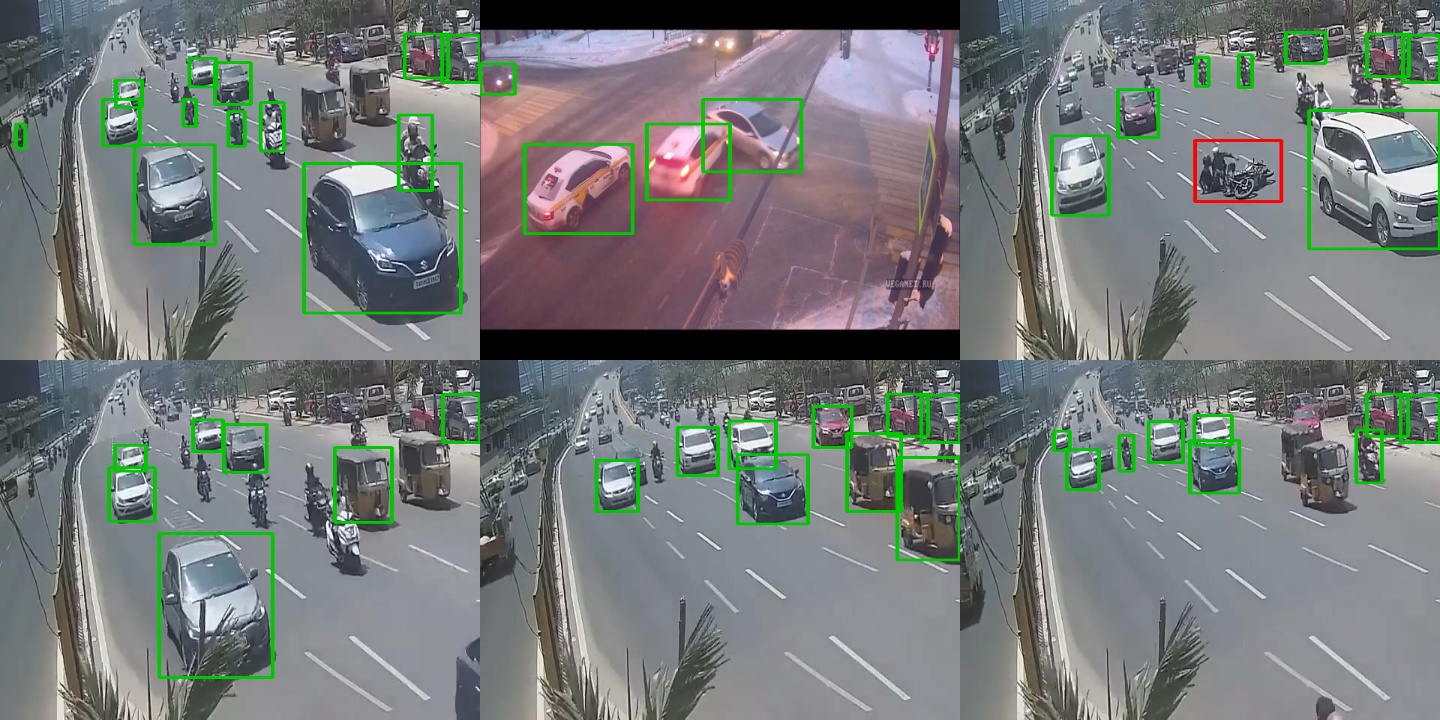

In [11]:
pseudo_label(OUT, cls, PSEUDO_MODEL, PSEUDO_CONF, PSEUDO_IMGSZ)

import cv2, numpy as np
from IPython.display import Image as IPImage, display

def check_samples(n=6):
    fs = sorted(Path(f'{OUT}/train/images').iterdir())
    tiles = []
    for f in random.sample(fs, min(n, len(fs))):
        im = cv2.imread(str(f)); h, w = im.shape[:2]
        for ln in open(f'{OUT}/train/labels/{f.stem}.txt'):
            c, x, y, bw, bh = ln.split(); x, y, bw, bh = float(x), float(y), float(bw), float(bh)
            cv2.rectangle(im, (int((x - bw / 2) * w), int((y - bh / 2) * h)), (int((x + bw / 2) * w), int((y + bh / 2) * h)),
                          (0, 0, 255) if cls_names[int(c)] == 'accident' else (0, 200, 0), 3)
        tiles.append(cv2.resize(im, (480, 360)))
    while len(tiles) % 3:
        tiles.append(np.zeros_like(tiles[0]))
    cv2.imwrite('/content/check_retrain.jpg', np.vstack([np.hstack(tiles[i:i + 3]) for i in range(0, len(tiles), 3)]))
    display(IPImage('/content/check_retrain.jpg', width=1000))

check_samples()

## 6. Retrain

In [12]:
model.train(data=f'{OUT}/data.yaml', epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=PATIENCE,
            optimizer='SGD', lr0=LR0, warmup_epochs=1, freeze=FREEZE or None,
            plots=True, project=RUNS, name=NAME, exist_ok=True)

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/retrain_work/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Project/Retrain_YOLO/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=retrain_rob

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  4,  6, 11])
area_ap: {}
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7932e3349e10>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0

## 7. Validation and plots

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,130,228 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2142.1±487.6 MB/s, size: 128.0 KB)
val: Scanning /content/retrain_work/dataset/val/labels.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 16.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.2it/s 3.4s
                   all         60        517      0.843      0.389      0.444      0.345
                   car         60        425      0.822      0.699      0.835       0.68
                 truck         14         14          1          0     0.0164     0.0147
            motorcycle          7          7          1          0     0.0203    0.00586
            pedestrian         31         41      0.396      0.244      0.348      0.264
              accident         30      

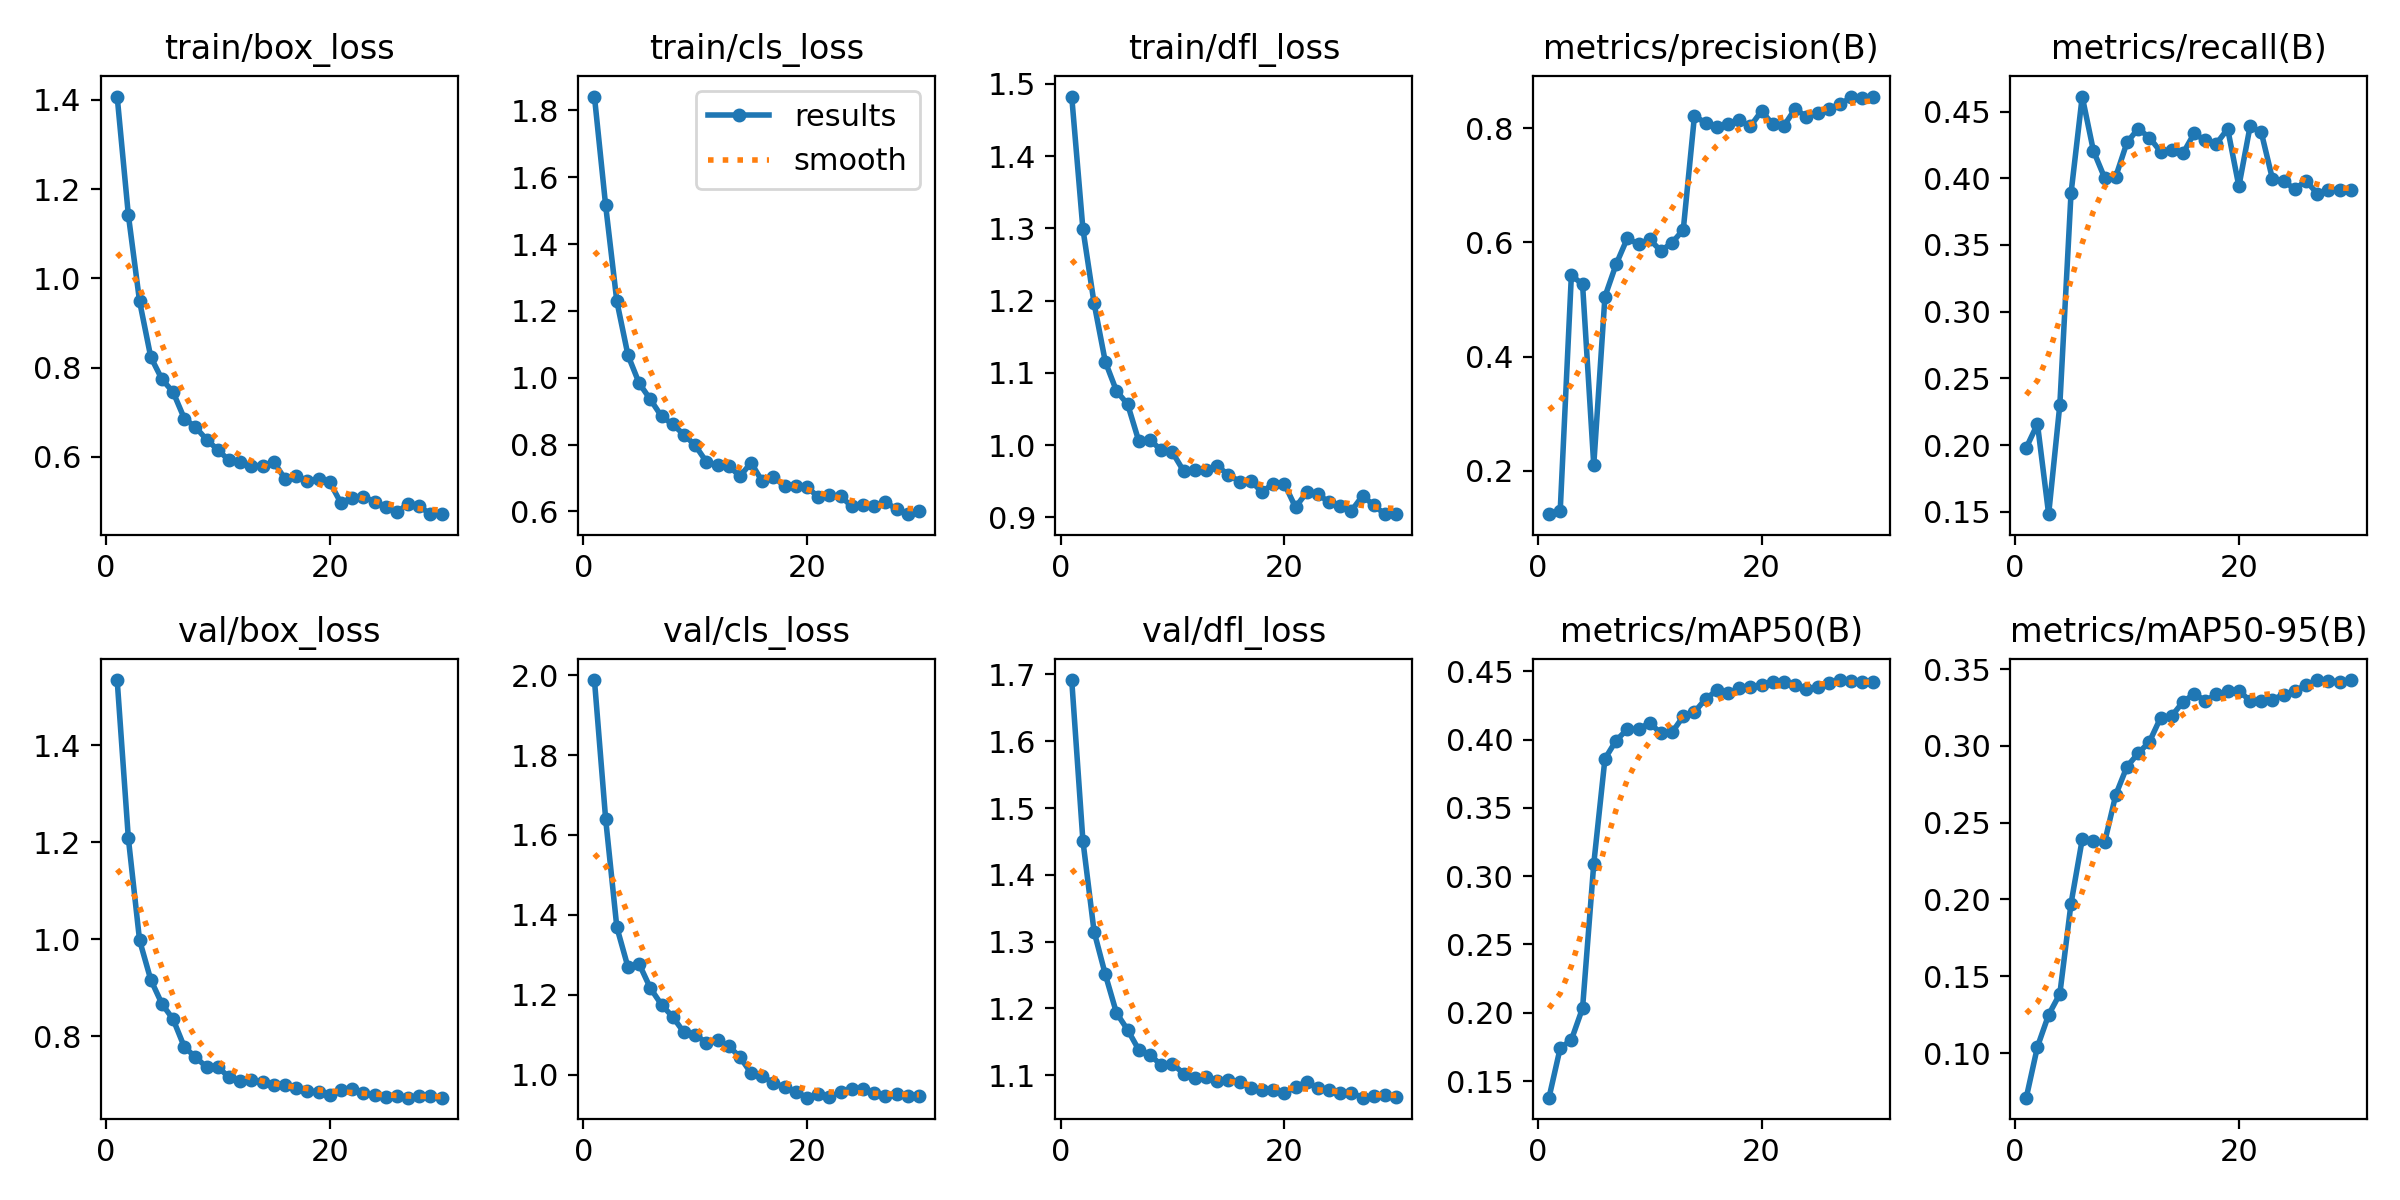

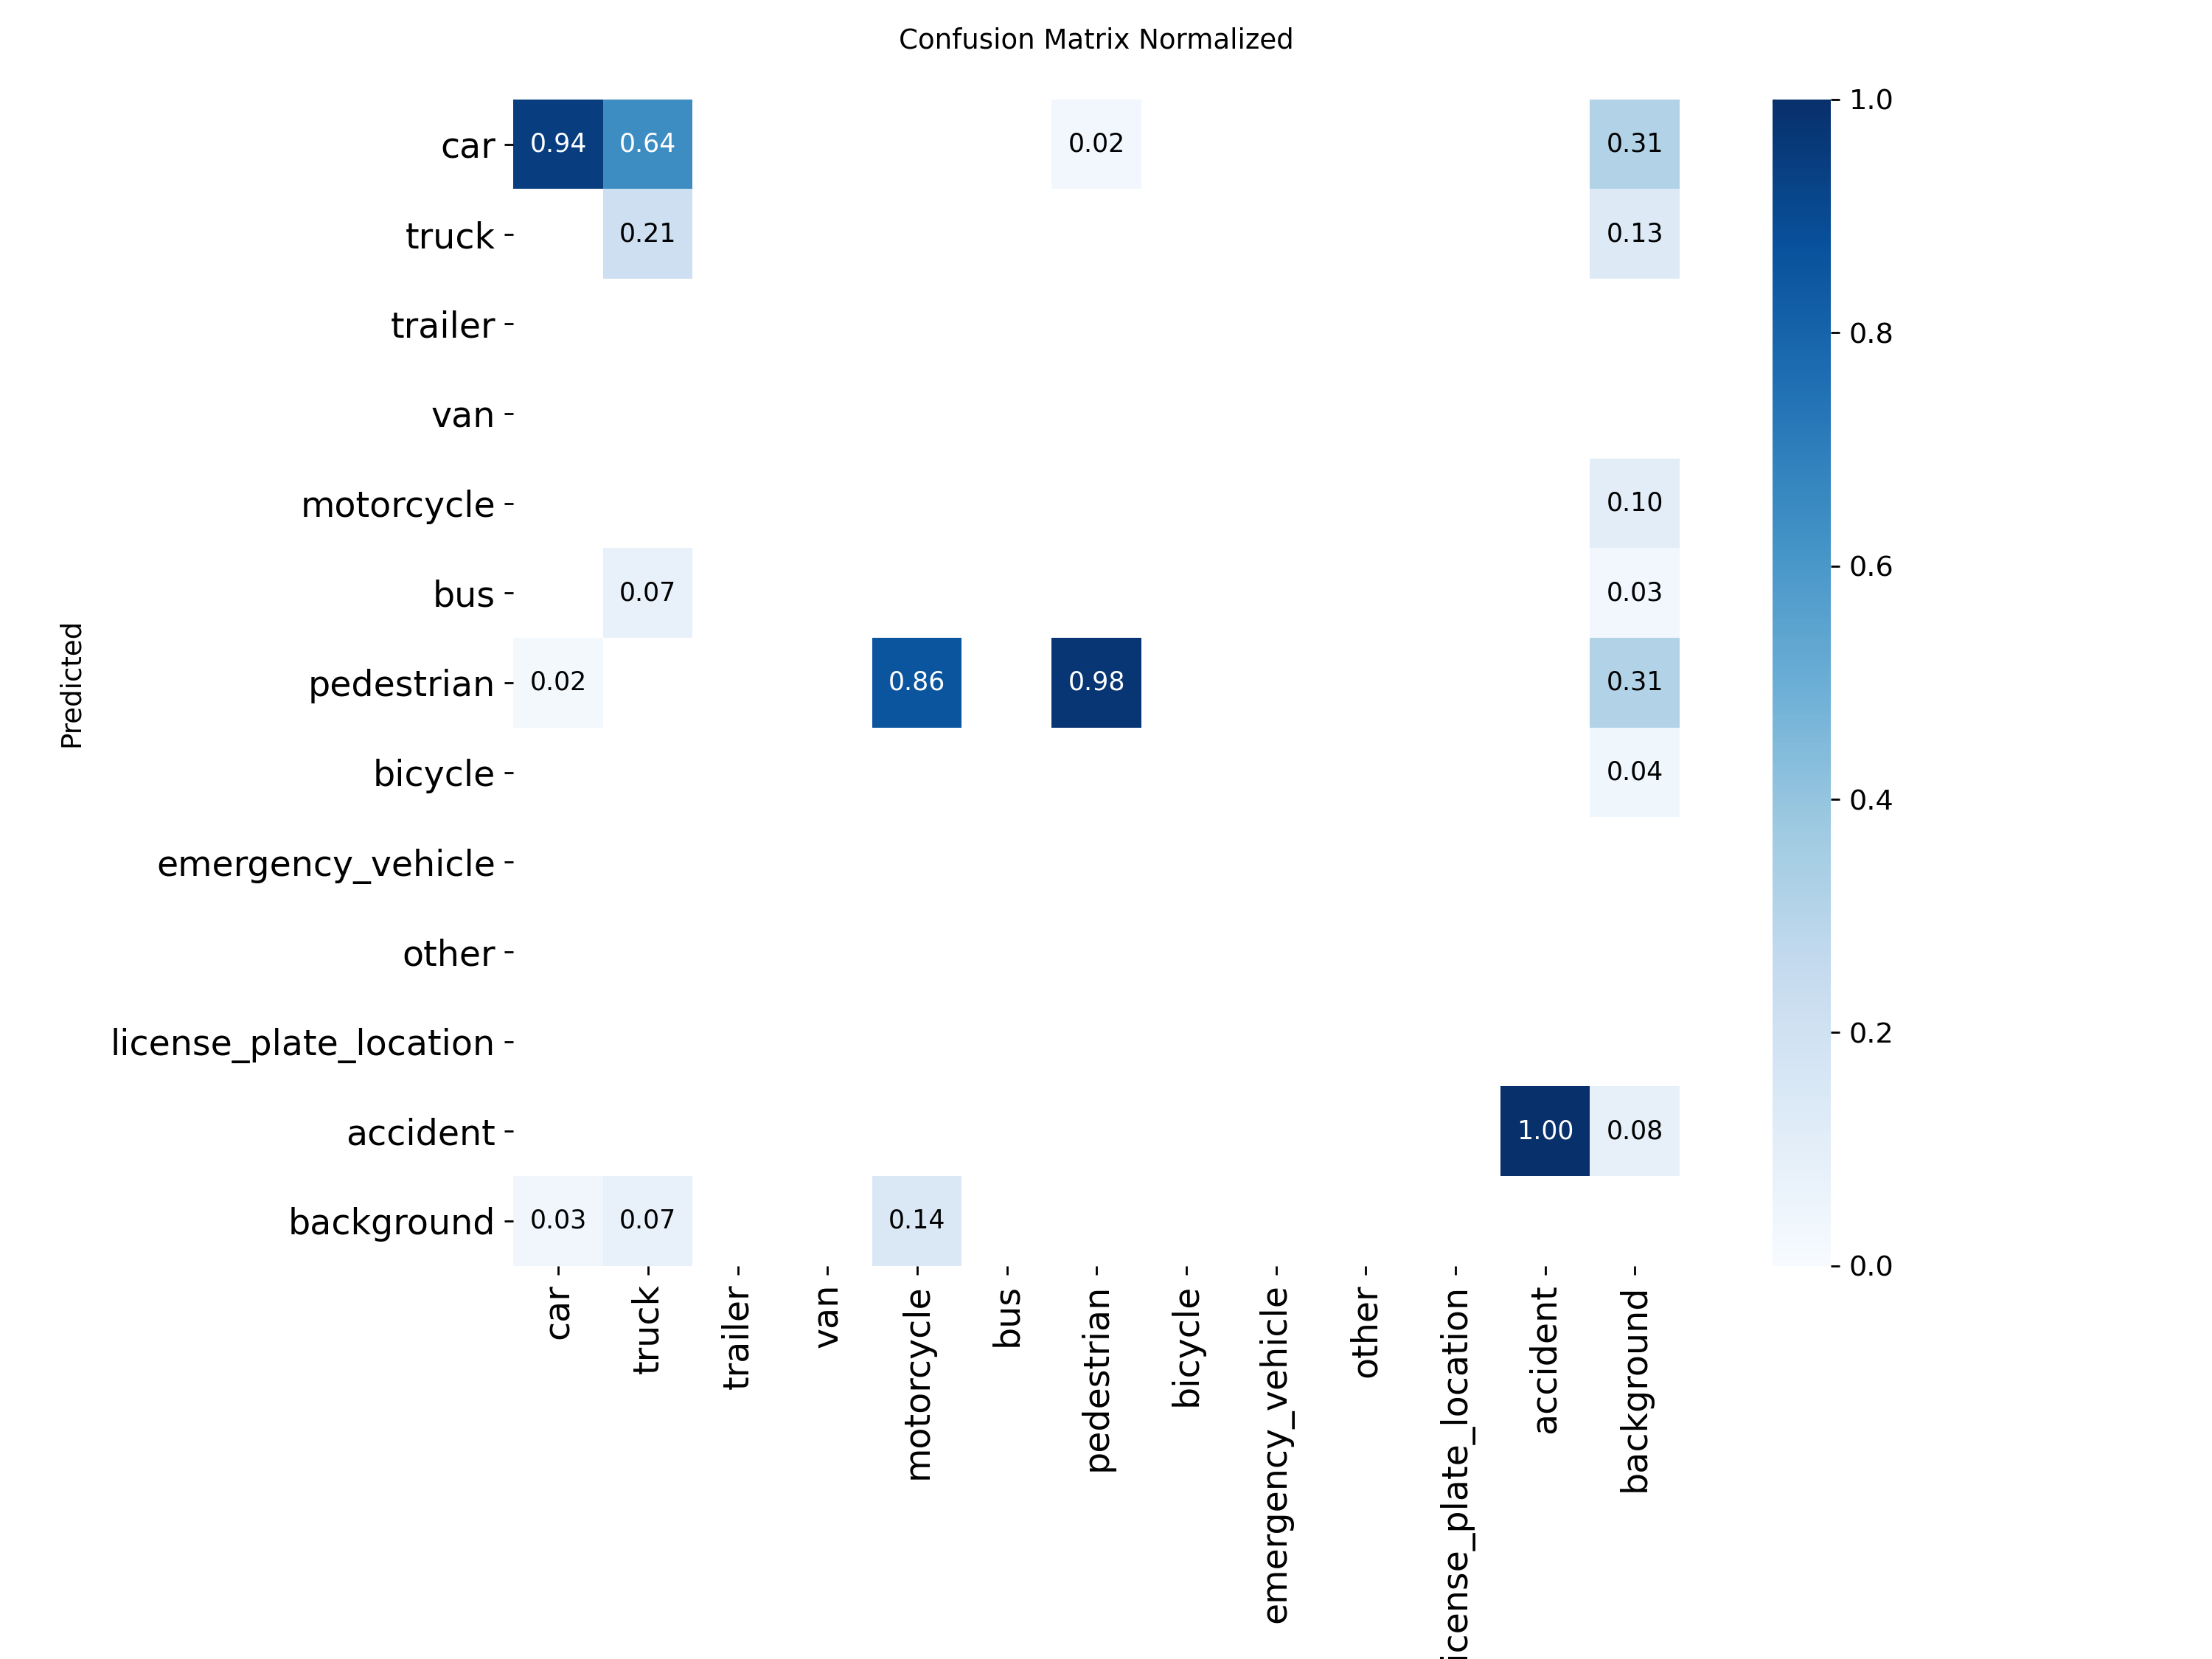

In [13]:
run = Path(RUNS) / NAME
best = run / 'weights' / 'best.pt'
YOLO(str(best)).val(data=f'{OUT}/data.yaml', imgsz=IMGSZ, project=RUNS, name=f'{NAME}_val', exist_ok=True)

for f in ('results.png', 'confusion_matrix_normalized.png'):
    if (run / f).exists():
        display(IPImage(str(run / f), width=900))

## 8. Save to Drive
The original `best.pt` stays untouched.

In [14]:
dst = Path(SAVE_DIR)
dst.mkdir(parents=True, exist_ok=True)
shutil.copy(best, dst / 'best_retrain.pt')
for f in ('results.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png'):
    if (run / f).exists():
        shutil.copy(run / f, dst / f)
print('Saved to', dst)

Saved to /content/drive/MyDrive/tumtraf/retrain
